# 06 · Faire le plein ou recharger ?

Les cinq premiers notebooks portaient sur les carburants. Celui-ci passe à la voiture électrique, avec trois sources publiques de plus : le **fichier consolidé des bornes de recharge** (IRVE, data.gouv.fr), les **voitures immatriculées par commune et par type de recharge** (Agence ORE, d'après AAA Data) et le **prix de l'électricité des ménages** (Eurostat). Les communes et leur population viennent de l'API Découpage administratif.

**Questions**
1. Combien de points de charge publics, de quelle puissance, pour combien de voitures électriques ?
2. Les bornes sont-elles là où vivent les gens et les voitures électriques ?
3. Les « déserts » : à quelle distance de la recharge rapide la plus proche vivent les habitants, comparé à la station-service la plus proche ?
4. Combien coûtent 100 km en électrique et au gazole, à domicile et sur borne, aujourd'hui et depuis 2007 ?

Le périmètre est la France métropolitaine, Corse comprise. Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date, timedelta
import json
from pathlib import Path

import h3
from IPython.display import Markdown, display
from matplotlib.collections import PolyCollection
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.neighbors import BallTree

from carburants import analyse, bornes, territoires

DONNEES = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
chiffres = {}

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def virgule(valeur, _=None, decimales=None):
    texte = f"{valeur:g}" if decimales is None else f"{valeur:.{decimales}f}"
    return texte.replace(".", ",").replace("-", "−")

def pondere(valeurs, poids, q=50):
    """Quantile pondéré (par la population, par exemple)."""
    ordre = np.argsort(valeurs)
    cumul = np.cumsum(np.asarray(poids, dtype=float)[ordre])
    return float(np.asarray(valeurs)[ordre][np.searchsorted(cumul, cumul[-1] * q / 100)])

## Les données

Le fichier consolidé des bornes agrège les déclarations de centaines d'aménageurs, et il en garde les défauts : des points de charge déclarés deux fois, des puissances en watts au lieu de kilowatts, des booléens écrits de dix façons, un tarif en texte libre. `carburants.bornes.nettoyer` ramène tout cela à une ligne par point de charge (la déclaration la plus récente), avec une puissance en kW et, quand le texte du tarif le permet, un prix par kWh.

In [2]:
fichier_irve = sorted((DONNEES / "irve").glob("bornes_*.parquet"))[-1]
irve = pl.read_parquet(fichier_irve)
JOUR = date.fromisoformat(fichier_irve.stem.removeprefix("bornes_"))
points_tous = bornes.nettoyer(irve, aujourd_hui=JOUR)
puissance_brute = irve["puissance_nominale"].cast(pl.Float64, strict=False)

chiffres["lignes_irve"] = irve.height
chiffres["points"] = points_tous.height
chiffres["doublons"] = irve.height - points_tous.height
chiffres["puissances_watts"] = int(((puissance_brute >= 1000) & (puissance_brute / 1000 <= 400)).sum())
chiffres["part_puissance_inconnue"] = float(points_tous["puissance_kw"].is_null().mean() * 100)
chiffres["part_sans_date"] = float(points_tous["mise_en_service"].is_null().mean() * 100)
chiffres["part_tarif_lisible"] = float(points_tous["prix_kwh"].is_not_null().mean() * 100)
chiffres["part_hors_metropole"] = float((~points_tous["metropole"]).mean() * 100)

# Le périmètre : métropole, accès public (l'accès réservé aux clients ou résidents est écarté)
points = points_tous.filter(pl.col("metropole"), ~pl.col("acces_reserve").fill_null(False))
chiffres["part_acces_reserve"] = float(points_tous.filter("metropole")["acces_reserve"].fill_null(False).mean() * 100)
chiffres["points_publics"] = points.height
stations_recharge = bornes.stations_recharge(points)
chiffres["stations_recharge"] = stations_recharge.height
print(f"{irve.height:,} lignes, {points_tous.height:,} points de charge distincts, {points.height:,} publics en métropole, "
      f"{stations_recharge.height:,} stations de recharge (fichier du {JOUR})")

# Communes de métropole avec leur population et leur centre ; les arrondissements servent aux voitures
communes_toutes = pl.read_parquet(DONNEES / "territoires" / "communes.parquet")
communes = communes_toutes.filter(
    pl.col("type") == "commune-actuelle", pl.col("population").is_not_null(), pl.col("latitude").is_not_null(),
    bornes.en_metropole(pl.col("longitude"), pl.col("latitude")),
)
population = communes["population"].to_numpy()
chiffres["communes"] = communes.height
chiffres["population"] = float(population.sum())

# Stations-service : celles qui ont publié un prix dans les 30 derniers jours de l'historique
HISTORIQUE = DONNEES / "historique"
prix_recents = analyse.charger_historique(HISTORIQUE, [JOUR.year])
dernier_prix = prix_recents.select(pl.col("maj").max()).collect().item()
actives = prix_recents.filter(pl.col("maj") >= dernier_prix - timedelta(days=30)).select("station_id").unique().collect()
stations_service = (
    analyse.stations_connues(HISTORIQUE).rename({"id": "station_id"}).join(actives, on="station_id")
    .filter(bornes.en_metropole(pl.col("longitude"), pl.col("latitude")))
)
chiffres["stations_service"] = stations_service.height
pl.DataFrame({
    "étape": ["lignes du fichier", "points de charge distincts", "dont puissance en watts corrigée", "points publics en métropole",
              "stations de recharge publiques", "stations-service actives"],
    "nombre": [irve.height, points_tous.height, chiffres["puissances_watts"], points.height, stations_recharge.height, stations_service.height],
})

157,460 lignes, 149,540 points de charge distincts, 132,901 publics en métropole, 44,102 stations de recharge (fichier du 2026-10-19)


étape,nombre
str,i64
"""lignes du fichier""",157460
"""points de charge distincts""",149540
"""dont puissance en watts corrig…",89
"""points publics en métropole""",132901
"""stations de recharge publiques""",44102
"""stations-service actives""",9413


Le fichier compte 157 460 lignes pour 149 540 points de charge distincts : 7 920 lignes sont des doublons : le même point publié par deux sources, l'opérateur ou la collectivité d'une part, une plateforme d'agrégation (Gireve, Eco-Movement…) d'autre part. On garde alors la déclaration de l'opérateur. 89 puissances étaient en watts. La puissance reste inconnue pour 1,6 % des points, la date de mise en service pour 42 %, et seuls 10 % des points ont un tarif lisible en euros par kWh. On garde les points de métropole en accès public (11 % des points sont réservés à une clientèle) : **132 901 points de charge**, regroupés en 44 102 stations de recharge.

## 1. Le réseau de recharge

Les points de charge se rangent par puissance, de la prise renforcée (jusqu'à 7,4 kW, une nuit pour un plein) à la recharge ultra-rapide (150 kW et plus, une pause de vingt minutes). Seule la recharge **rapide**, à partir de 50 kW, remplace vraiment un passage à la pompe sur un trajet.

In [3]:
ORDRE = list(bornes.CLASSES_PUISSANCE)
par_classe = (
    points.group_by("classe").agg(points=pl.len())
    .join(stations_recharge.group_by("classe").agg(stations=pl.len()), on="classe", how="full", coalesce=True)
    .filter(pl.col("classe").is_not_null())
    .with_columns(rang=pl.col("classe").replace_strict({nom: k for k, nom in enumerate(ORDRE)}, return_dtype=pl.Int32))
    .sort("rang").drop("rang")
    .with_columns(part_points=(pl.col("points") / pl.col("points").sum() * 100).round(1))
)
rapides = stations_recharge.filter(pl.col("puissance_max_kw") >= bornes.RAPIDE_KW)
ultra = stations_recharge.filter(pl.col("puissance_max_kw") >= 150)
chiffres["points_rapides"] = points.filter(pl.col("puissance_kw") >= bornes.RAPIDE_KW).height
chiffres["part_points_rapides"] = chiffres["points_rapides"] / points.height * 100
chiffres["part_points_7_22"] = par_classe.filter(classe="7,4 à 22 kW")["part_points"].item()
chiffres["stations_rapides"] = rapides.height
chiffres["stations_ultra"] = ultra.height
# Plusieurs stations déclarées peuvent partager un même lieu (deux opérateurs sur un parking) : on regroupe les
# stations à moins de 150 m l'une de l'autre en sites, pour la recharge rapide comme pour les stations-service
chiffres["sites_rapides"] = int(bornes.sites(rapides).max() + 1)
chiffres["sites_stations_service"] = int(bornes.sites(stations_service).max() + 1)
chiffres["sites_rapides_pour_100"] = chiffres["sites_rapides"] / chiffres["sites_stations_service"] * 100

# Voitures rechargeables (électriques et hybrides rechargeables), par trimestre
vehicules = territoires.lire_vehicules(DONNEES / "territoires" / "vehicules" / "Fichier_csv.csv")
vehicules = vehicules.with_columns(departement=pl.col("code_insee").str.slice(0, 2)).join(
    communes_toutes.select("code_insee", "population"), on="code_insee", how="left"
)
metro = ~pl.col("departement").str.starts_with("97")
parc = vehicules.filter(metro).group_by("date").agg(pl.col("electriques").sum()).sort("date")
DATE_PARC = parc["date"].max()
chiffres["parc_debut"] = parc["electriques"][0] / 1e6
chiffres["parc_fin"] = parc["electriques"][-1] / 1e6
chiffres["parc_multiplie"] = parc["electriques"][-1] / parc["electriques"][0]
chiffres["voitures_par_point"] = parc["electriques"][-1] / points.height
chiffres["voitures_par_point_rapide"] = parc["electriques"][-1] / chiffres["points_rapides"]
print(f"Parc rechargeable au {DATE_PARC} : {parc['electriques'][-1]:,} voitures")
par_classe

Parc rechargeable au 2026-08-31 : 2,717,082 voitures


classe,points,stations,part_points
str,u32,u32,f64
"""jusqu'à 7,4 kW""",19445,5513,14.6
"""7,4 à 22 kW""",72718,25144,54.7
"""22 à 50 kW""",6368,3939,4.8
"""50 à 150 kW""",12938,4743,9.7
"""150 kW et plus""",21351,4761,16.1


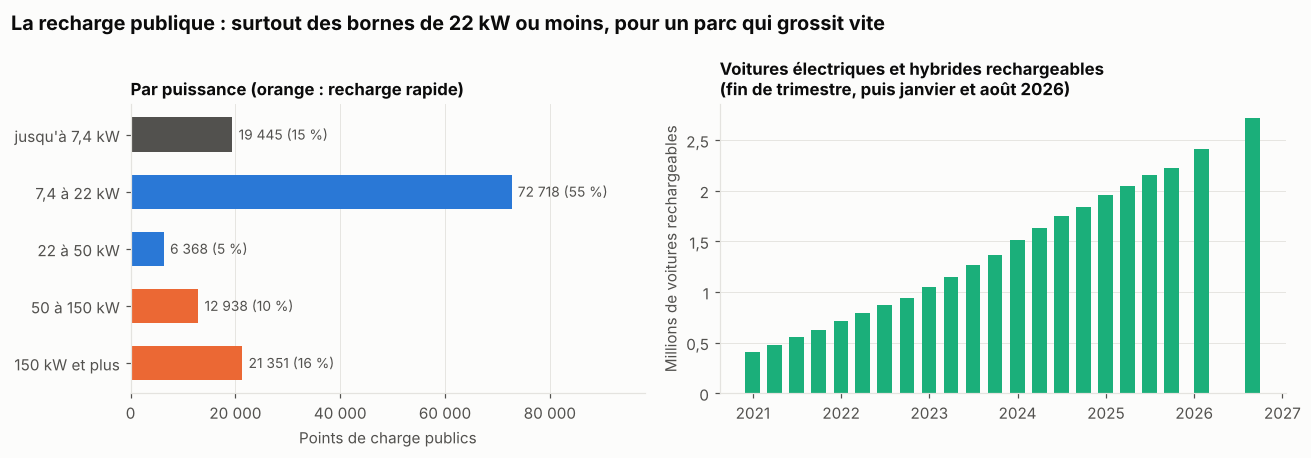

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
couleurs = [TEXTE_2, BLEU, BLEU, ORANGE, ORANGE]
ax.barh(par_classe["classe"].to_list()[::-1], par_classe["points"].to_list()[::-1], color=couleurs[::-1], height=0.6)
for yi, (n, part) in enumerate(zip(par_classe["points"].to_list()[::-1], par_classe["part_points"].to_list()[::-1])):
    ax.annotate(f"{n:,}".replace(",", " ") + f" ({virgule(part, decimales=0)} %)", (n, yi), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9, color=TEXTE_2)
ax.set_xlabel("Points de charge publics")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
ax.set_xlim(0, par_classe["points"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title("Par puissance (orange : recharge rapide)", fontsize=11)

ax = axes[1]
ax.bar(parc["date"].to_list(), (parc["electriques"] / 1e6).to_list(), width=60, color=AQUA)
ax.set_ylabel("Millions de voitures rechargeables")
ax.yaxis.set_major_formatter(virgule)
ax.set_title("Voitures électriques et hybrides rechargeables\n(fin de trimestre, puis janvier et août 2026)", fontsize=11)
ax.grid(axis="x", visible=False)
fig.suptitle("La recharge publique : surtout des bornes de 22 kW ou moins, pour un parc qui grossit vite",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "21_bornes_reseau")

Les bornes de 7,4 à 22 kW, celles des parkings et de la voirie, font 55 % des points de charge publics. La recharge rapide (50 kW et plus) en représente un quart (26 %) : 34 289 points, répartis dans 9 504 stations déclarées, dont 4 761 offrent au moins 150 kW. Une fois regroupées les stations voisines de moins de 150 m (deux opérateurs sur un même parking, par exemple), cela fait **7 388 sites** de recharge rapide, contre 9 189 sites de stations-service actives (9 413 stations) : 80 sites de recharge rapide pour 100 stations-service.

En face, le parc de voitures rechargeables (électriques et hybrides rechargeables) est passé de 0,41 million fin 2020 à 2,72 millions, 6,6 fois plus. On compte aujourd'hui 20 voitures rechargeables par point de charge public et 79 par point de charge rapide ; la plupart rechargent chez elles ou au travail.

## 2. Les bornes suivent-elles les habitants et les voitures ?

On rattache chaque point de charge à son département (par le code de commune déclaré, à défaut par la commune dont le centre est le plus proche), puis on rapporte le nombre de points à la population et au nombre de voitures rechargeables.

Un piège : les voitures sont comptées à l'adresse de leur titulaire, et les flottes d'entreprise ou de location sont immatriculées au siège. Quelques communes comptent ainsi bien plus de voitures que d'habitants (Poissy, Rueil-Malmaison, Montigny-le-Bretonneux…). On écarte du compte départemental les communes de plus de 2 000 voitures qui en comptent plus de deux par habitant.

In [5]:
# Département de chaque point : code de commune déclaré, sinon commune (ou arrondissement) la plus proche
reperes = communes_toutes.filter(
    pl.col("latitude").is_not_null(), ~pl.col("code_insee").is_in(["75056", "13055", "69123"])
)
arbre_communes = BallTree(np.radians(reperes.select("latitude", "longitude").to_numpy()), metric="haversine")
_, indice = arbre_communes.query(np.radians(points.select("latitude", "longitude").to_numpy()), k=1)
points = points.with_columns(departement_proche=pl.Series(reperes["departement"].to_numpy()[indice[:, 0]])).join(
    communes_toutes.select("code_insee", pl.col("departement").alias("departement_declare")), on="code_insee", how="left"
).with_columns(departement=pl.coalesce("departement_declare", "departement_proche"))
chiffres["part_departement_declare"] = float(points["departement_declare"].is_not_null().mean() * 100)

recents = vehicules.filter(pl.col("date") == DATE_PARC, metro)
sieges = recents.filter(pl.col("voitures") > 2000, pl.col("voitures") > 2 * pl.col("population"))
chiffres["sieges_communes"] = sieges.height
chiffres["sieges_electriques"] = float(sieges["electriques"].sum() / recents["electriques"].sum() * 100)
residents = recents.join(sieges.select("code_insee"), on="code_insee", how="anti")

par_departement = (
    communes.group_by("departement").agg(population=pl.col("population").sum())
    .join(points.group_by("departement").agg(points=pl.len(), rapides=(pl.col("puissance_kw") >= bornes.RAPIDE_KW).sum()),
          on="departement", how="left")
    .join(residents.group_by("departement").agg(electriques=pl.col("electriques").sum()), on="departement", how="left")
    .with_columns(pl.col("points", "rapides", "electriques").fill_null(0))
    .with_columns(
        nom=pl.col("departement").replace_strict(territoires.DEPARTEMENTS, default=None),
        points_10k=pl.col("points") / pl.col("population") * 1e4,
        rapides_100k=pl.col("rapides") / pl.col("population") * 1e5,
        ve_1000=pl.col("electriques") / pl.col("population") * 1e3,
        ve_par_point=pl.col("electriques") / pl.col("points"),
    )
    .sort("points_10k")
)
assert par_departement["nom"].null_count() == 0 and par_departement.height == 96
chiffres["points_10k_france"] = points.height / population.sum() * 1e4
chiffres["correlation_ve_points"] = float(np.corrcoef(par_departement["ve_1000"], par_departement["points_10k"])[0, 1])
assert abs(chiffres["correlation_ve_points"]) < 0.3
assert par_departement["nom"].to_list()[-3:] == ["Tarn", "Vienne", "Hautes-Alpes"]
assert "Seine-Saint-Denis" in par_departement["nom"].to_list()[:3]
chiffres["points_10k_min"], chiffres["points_10k_max"] = par_departement["points_10k"].min(), par_departement["points_10k"].max()
chiffres["ve_par_point_min"], chiffres["ve_par_point_max"] = par_departement["ve_par_point"].min(), par_departement["ve_par_point"].max()
for nom, ligne in [("moins", par_departement.row(0, named=True)), ("plus", par_departement.row(-1, named=True))]:
    chiffres[f"points_10k_{nom}_equipe"] = ligne["points_10k"]
par_ve = par_departement.sort("ve_par_point")
display(Markdown(
    f"Département le moins équipé : **{par_departement['nom'][0]}** ({virgule(par_departement['points_10k'][0], decimales=1)} points pour 10 000 habitants) ; "
    f"le plus équipé : **{par_departement['nom'][-1]}** ({virgule(par_departement['points_10k'][-1], decimales=1)}). "
    f"Le moins de voitures rechargeables par point : **{par_ve['nom'][0]}** ({par_ve['ve_par_point'][0]:.0f}) ; "
    f"le plus : **{par_ve['nom'][-1]}** ({par_ve['ve_par_point'][-1]:.0f})."
))
par_departement.select("departement", "nom", "population", "points", "points_10k", "rapides_100k", "ve_1000", "ve_par_point").with_columns(
    pl.col("points_10k", "rapides_100k", "ve_1000", "ve_par_point").round(1)
)

Département le moins équipé : **Haute-Saône** (8,6 points pour 10 000 habitants) ; le plus équipé : **Hautes-Alpes** (39,5). Le moins de voitures rechargeables par point : **Lozère** (8) ; le plus : **Hauts-de-Seine** (47).

departement,nom,population,points,points_10k,rapides_100k,ve_1000,ve_par_point
str,str,i64,u32,f64,f64,f64,f64
"""70""","""Haute-Saône""",233185,200,8.6,47.6,25.7,30.0
"""93""","""Seine-Saint-Denis""",1704316,1489,8.7,18.5,22.1,25.3
"""55""","""Meuse""",180290,204,11.3,35.5,27.0,23.9
"""24""","""Dordogne""",417614,535,12.8,41.7,32.7,25.5
"""43""","""Haute-Loire""",228654,300,13.1,24.9,30.4,23.1
"""47""","""Lot-et-Garonne""",333602,470,14.1,46.8,33.9,24.1
"""37""","""Indre-et-Loire""",619362,899,14.5,57.5,37.5,25.8
"""64""","""Pyrénées-Atlantiques""",706564,1027,14.5,46.4,35.1,24.2
"""53""","""Mayenne""",305468,451,14.8,28.5,34.0,23.0


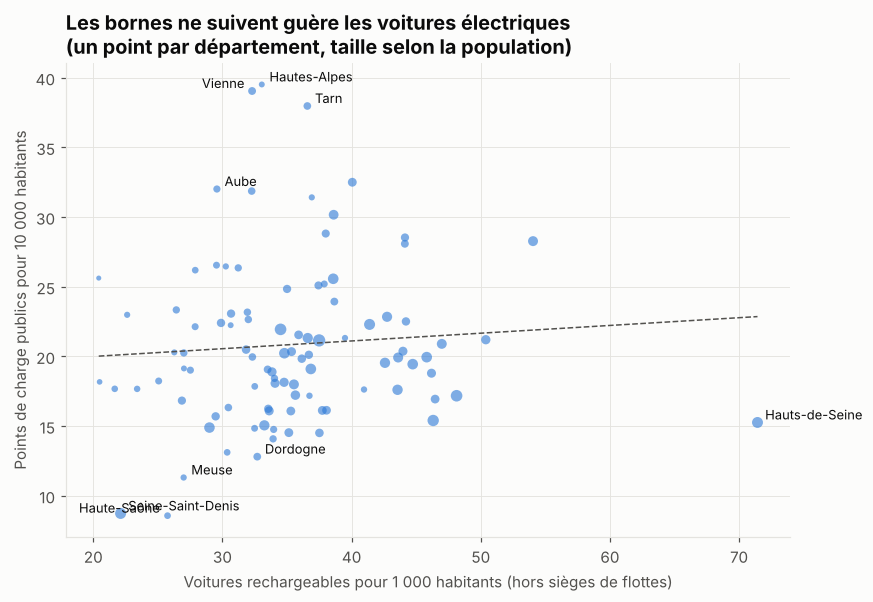

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
x, y = par_departement["ve_1000"].to_numpy(), par_departement["points_10k"].to_numpy()
ax.scatter(x, y, s=np.sqrt(par_departement["population"].to_numpy()) / 25, color=BLEU, alpha=0.6, linewidths=0)
pente, origine = np.polyfit(x, y, 1)
grille_x = np.linspace(x.min(), x.max(), 50)
ax.plot(grille_x, origine + pente * grille_x, color=TEXTE_2, linewidth=1, linestyle="--")
residu = y - (origine + pente * x)
places = []
for k in sorted(set(np.argsort(residu)[:4]) | set(np.argsort(residu)[-4:]) | {int(np.argmax(x))}, key=lambda k: -y[k]):
    # Une étiquette trop proche d'une autre passe à gauche du point
    gauche = any(abs(x[k] - xp) < 4 and abs(y[k] - yp) < 1.5 for xp, yp in places)
    ax.annotate(par_departement["nom"][int(k)], (x[k], y[k]), xytext=(-5 if gauche else 5, 2), textcoords="offset points",
                ha="right" if gauche else "left", fontsize=8.5, color=TEXTE)
    places.append((x[k], y[k]))
ax.set_xlabel("Voitures rechargeables pour 1 000 habitants (hors sièges de flottes)")
ax.set_ylabel("Points de charge publics pour 10 000 habitants")
ax.xaxis.set_major_formatter(virgule)
ax.yaxis.set_major_formatter(virgule)
ax.set_title("Les bornes ne suivent guère les voitures électriques\n(un point par département, taille selon la population)")
sauver(fig, "22_bornes_departements")

En moyenne, la métropole compte 20,1 points de charge publics pour 10 000 habitants, de 8,6 à 39,5 selon le département (le tableau et la phrase ci-dessus nomment les extrêmes). **Les bornes ne suivent guère les voitures** : d'un département à l'autre, le nombre de points par habitant et le nombre de voitures rechargeables par habitant sont presque sans rapport (corrélation de 0,07), et le nombre de voitures rechargeables par point public va de 8 à 47. Les mieux équipés par habitant sont des départements plutôt ruraux (Hautes-Alpes, Vienne, Tarn), tandis que la Seine-Saint-Denis, très dense, est l'un des moins équipés : le déploiement semble dépendre des choix locaux (communes, syndicats départementaux d'énergie, opérateurs) plus que du nombre de voitures à recharger. Écarter les 36 communes « sièges de flottes » retire 7 % des voitures rechargeables du compte ; les Hauts-de-Seine, isolés à droite du graphique, restent gonflés par les flottes de La Défense, que la règle ne détecte pas. Le code de commune déclaré par l'aménageur rattache 61 % des points ; les autres le sont par la commune la plus proche.

## 3. Les déserts de recharge rapide

Pour chaque commune, on mesure la distance à vol d'oiseau entre son centre et la station la plus proche de chaque type, puis on pondère par la population. On compare la recharge rapide (50 kW et plus) et ultra-rapide (150 kW et plus) à la station-service. Le centre de la commune est une approximation : dans une grande commune, certains habitants sont plus loin, d'autres plus près.

In [7]:
CIBLES = {
    "station-service": stations_service,
    "toute borne publique": stations_recharge,
    "recharge rapide (50 kW et plus)": rapides,
    "recharge ultra-rapide (150 kW et plus)": ultra,
}
CLES = dict(zip(CIBLES, ["station", "borne", "rapide", "ultra"]))
SEUILS = [5, 10, 15, 20]
distances, lignes = {}, []
for nom, cibles in CIBLES.items():
    d = bornes.distance_plus_proche_km(communes, cibles)
    distances[nom] = d
    parts = bornes.part_population_au_dela(d, population, SEUILS)
    ligne = {"la plus proche": nom, "distance médiane (km)": round(pondere(d, population), 1)}
    ligne.update({f"> {s} km (% hab.)": round(p, 1) for s, p in parts.items()})
    lignes.append(ligne)
    chiffres[f"mediane_{CLES[nom]}"] = pondere(d, population)
    for s, p in parts.items():
        chiffres[f"au_dela_{s}_{CLES[nom]}"] = p
d_station, d_rapide = distances["station-service"], distances["recharge rapide (50 kW et plus)"]
plus_loin = d_rapide - d_station > 10
chiffres["communes_rapide_plus_loin"] = int(plus_loin.sum())
chiffres["habitants_rapide_plus_loin"] = float(population[plus_loin].sum() / 1e6)
chiffres["habitants_10_rapide"] = float(population[d_rapide > 10].sum() / 1e6)
chiffres["habitants_10_station"] = float(population[d_station > 10].sum() / 1e6)
assert chiffres["au_dela_10_rapide"] > chiffres["au_dela_10_station"]

# Par département : part des habitants à plus de 15 km d'une recharge rapide
loin = communes.with_columns(loin=pl.Series(d_rapide > 15), population_=pl.col("population"))
deserts = (
    loin.group_by("departement")
    .agg(part=(pl.col("population_") * pl.col("loin")).sum() / pl.col("population_").sum() * 100)
    .with_columns(nom=pl.col("departement").replace_strict(territoires.DEPARTEMENTS, default=None))
    .sort("part", descending=True)
)
chiffres["deserts_departement_max"] = deserts["part"][0]
chiffres["departements_sans_desert"] = int((deserts["part"] == 0).sum())
display(Markdown(
    "Les départements où la part d'habitants à plus de 15 km d'une recharge rapide est la plus forte : "
    + ", ".join(f"**{n}** ({virgule(p, decimales=0)} %)" for n, p in deserts.head(5).select("nom", "part").iter_rows()) + "."
))
pl.DataFrame(lignes)

Les départements où la part d'habitants à plus de 15 km d'une recharge rapide est la plus forte : **Lozère** (27 %), **Meuse** (14 %), **Indre** (14 %), **Haute-Marne** (13 %), **Haute-Saône** (13 %).

la plus proche,distance médiane (km),> 5 km (% hab.),> 10 km (% hab.),> 15 km (% hab.),> 20 km (% hab.)
str,f64,f64,f64,f64,f64
"""station-service""",1.2,11.2,1.1,0.1,0.0
"""toute borne publique""",0.7,7.1,1.0,0.1,0.0
"""recharge rapide (50 kW et plus…",1.6,20.6,5.7,1.3,0.2
"""recharge ultra-rapide (150 kW …",2.2,30.1,13.3,5.0,1.8


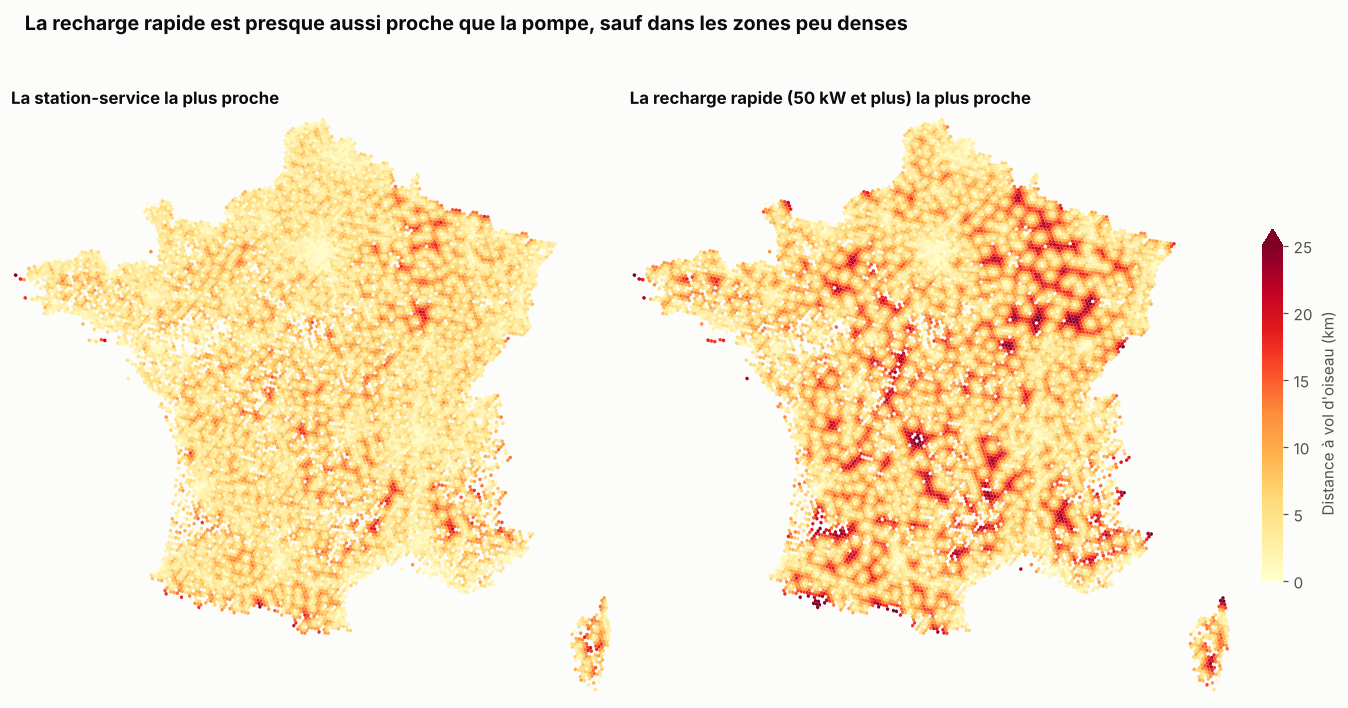

In [8]:
# Carte : une grille hexagonale H3 (résolution 6, environ 36 km² par cellule) sur les zones habitées
RESOLUTION = 6
cellules = sorted({h3.latlng_to_cell(la, lo, RESOLUTION) for la, lo in communes.select("latitude", "longitude").iter_rows()})
centres = np.array([h3.cell_to_latlng(cellule) for cellule in cellules])
polygones = [[(lo, la) for la, lo in h3.cell_to_boundary(cellule)] for cellule in cellules]
grille = pl.DataFrame({"latitude": centres[:, 0], "longitude": centres[:, 1]})
chiffres["cellules_h3"] = len(cellules)

fig = plt.figure(figsize=(12.5, 6.4))
axes = [fig.add_axes([0.0, 0.0, 0.44, 0.86]), fig.add_axes([0.45, 0.0, 0.44, 0.86])]
for ax, (titre, cibles) in zip(axes, [("La station-service la plus proche", stations_service),
                                      ("La recharge rapide (50 kW et plus) la plus proche", rapides)]):
    d = bornes.distance_plus_proche_km(grille, cibles)
    collection = PolyCollection(polygones, array=d, cmap="YlOrRd", linewidths=0)
    collection.set_clim(0, 25)
    ax.add_collection(collection)
    ax.set_xlim(-5.2, 9.7)
    ax.set_ylim(41.3, 51.2)
    ax.set_aspect(1 / np.cos(np.radians(46.5)))
    ax.set_axis_off()
    ax.set_title(titre, fontsize=11)
barre = fig.colorbar(collection, cax=fig.add_axes([0.91, 0.18, 0.015, 0.5]), extend="max")
barre.set_label("Distance à vol d'oiseau (km)", color=TEXTE_2)
barre.outline.set_visible(False)
fig.suptitle("La recharge rapide est presque aussi proche que la pompe, sauf dans les zones peu denses",
             x=0.01, y=0.99, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
sauver(fig, "23_bornes_deserts")

La moitié des habitants vit à moins de 1,2 km d'une station-service, et à moins de 1,6 km d'une recharge rapide : dans les villes, la recharge rapide est déjà presque aussi proche que la pompe. L'écart se creuse dans les zones peu denses : 5,7 % des habitants (3,7 millions) vivent à plus de 10 km d'une recharge rapide, contre 1,1 % (0,75 million) pour une station-service ; à plus de 15 km, 1,3 % contre 0,08 %. Pour l'ultra-rapide, 13 % des habitants sont à plus de 10 km.

Dans 1 785 communes (1,2 million d'habitants), la recharge rapide la plus proche est à plus de 10 km au-delà de la station-service la plus proche. Les déserts se concentrent dans les campagnes peu peuplées du Nord-Est, du Centre et du Massif central (la liste ci-dessus) ; dans le département le plus touché, 27 % des habitants sont à plus de 15 km d'une recharge rapide, tandis que dans 16 départements, aucune commune n'a son centre à plus de 15 km d'une recharge rapide.

## 4. Combien coûtent 100 km ?

On compare le coût de l'énergie pour parcourir 100 km, avec des consommations réalistes pour une voiture compacte, mesurées à la pompe et au compteur (pertes de recharge comprises) :

| Énergie | Consommation | Prix |
|---|---|---|
| Gazole | 5,5 litres | prix médian national de la semaine |
| SP95-E10 | 6,5 litres | prix médian national de la semaine |
| Électricité à domicile | 18 kWh | prix de référence des ménages (Eurostat, 2 500 à 5 000 kWh par an, toutes taxes, semestriel) |
| Électricité sur borne publique | 18 kWh | prix par kWh lu dans les tarifs déclarés, par puissance |

Les tarifs lisibles ne couvrent qu'une partie des bornes, et un seul opérateur (Lidl, avec deux prix uniques) en fournit une grande part pour la recharge lente et rapide : on retient donc, pour chaque puissance, la médiane des prix médians de chaque opérateur. C'est une indication, pas un relevé exhaustif ; les abonnements et les frais à la minute de certains réseaux ne sont pas comptés.

In [9]:
CONSO = {"gazole": 5.5, "e10": 6.5, "electrique": 18.0}
KM_PAR_AN = 12_000

def mediane_nationale(carburant):
    hebdo = analyse.prix_hebdo(analyse.charger_historique(HISTORIQUE).filter(pl.col("carburant") == carburant))
    return hebdo.group_by("semaine").agg(pl.col("prix").median().alias(carburant)).sort("semaine")

serie = mediane_nationale("Gazole").join(mediane_nationale("E10"), on="semaine", how="left")
electricite = pl.read_parquet(DONNEES / "territoires" / "prix_electricite.parquet").sort("debut")
serie = serie.join_asof(electricite.select("debut", "prix_eur_kwh"), left_on="semaine", right_on="debut").drop_nulls("prix_eur_kwh")
cout = serie.with_columns(
    gazole=pl.col("Gazole") * CONSO["gazole"],
    e10=pl.col("E10") * CONSO["e10"],
    domicile=pl.col("prix_eur_kwh") * CONSO["electrique"],
)

# Aujourd'hui : moyenne des quatre dernières semaines, et le dernier semestre publié par Eurostat
recent = cout.tail(4)
for cle in ["gazole", "e10", "domicile"]:
    chiffres[f"cout_{cle}"] = float(recent[cle].mean())
chiffres["prix_gazole"] = float(recent["Gazole"].mean())
chiffres["prix_kwh_domicile"] = float(electricite["prix_eur_kwh"][-1])
SEMESTRE = electricite["semestre"][-1]
lignes_tarifs = []
for nom, classe in {"lente": "7,4 à 22 kW", "rapide": "50 à 150 kW", "ultra": "150 kW et plus"}.items():
    dans_classe = points.filter(pl.col("classe") == classe)
    selection = dans_classe.filter(pl.col("prix_kwh").is_not_null())
    par_operateur = selection.group_by("operateur").agg(prix=pl.col("prix_kwh").median(), points=pl.len())
    chiffres[f"prix_kwh_{nom}"] = float(par_operateur["prix"].median())
    chiffres[f"prix_kwh_{nom}_brut"] = float(selection["prix_kwh"].median())
    chiffres[f"tarifs_{nom}"] = selection.height
    chiffres[f"couverture_{nom}"] = selection.height / dans_classe.height * 100
    chiffres[f"operateurs_{nom}"] = par_operateur.height
    chiffres[f"part_lidl_{nom}"] = float(selection["operateur"].str.to_lowercase().str.contains("lidl").mean() * 100)
    chiffres[f"cout_{nom}"] = chiffres[f"prix_kwh_{nom}"] * CONSO["electrique"]
    lignes_tarifs.append({"puissance": classe, "points avec tarif": selection.height,
                          "couverture (%)": round(chiffres[f"couverture_{nom}"], 1), "opérateurs": par_operateur.height,
                          "part Lidl (%)": round(chiffres[f"part_lidl_{nom}"], 1),
                          "médiane des points (€/kWh)": round(chiffres[f"prix_kwh_{nom}_brut"], 3),
                          "médiane des opérateurs (€/kWh)": round(chiffres[f"prix_kwh_{nom}"], 3)})
display(pl.DataFrame(lignes_tarifs))
chiffres["prix_kwh_equilibre"] = chiffres["cout_gazole"] / CONSO["electrique"]
chiffres["economie_an"] = (chiffres["cout_gazole"] - chiffres["cout_domicile"]) * KM_PAR_AN / 100
chiffres["ratio_domicile_gazole"] = chiffres["cout_domicile"] / chiffres["cout_gazole"] * 100
assert chiffres["cout_ultra"] < chiffres["cout_gazole"]

# Depuis 2007 (la série d'Eurostat commence au second semestre) : moyennes annuelles
annuel = (
    cout.group_by(pl.col("semaine").dt.year().alias("annee")).agg(pl.col("gazole", "domicile", "Gazole").mean())
    .with_columns(ratio=pl.col("domicile") / pl.col("gazole") * 100).sort("annee")
)
debut = annuel.row(0, named=True)
assert debut["annee"] == 2007 and cout["semaine"].min() >= date(2007, 7, 1)
chiffres["cout_gazole_debut"], chiffres["cout_domicile_debut"] = debut["gazole"], debut["domicile"]
chiffres["ratio_debut"] = debut["ratio"]
for annee in [2024, 2025]:
    chiffres[f"ratio_{annee}"] = annuel.filter(annee=annee)["ratio"].item()
chiffres["ratio_max"] = annuel["ratio"].max()
chiffres["annee_ratio_max"] = annuel.sort("ratio")["annee"][-1]
chiffres["prix_gazole_2025"] = annuel.filter(annee=2025)["Gazole"].item()
chiffres["prix_kwh_equilibre_2025"] = chiffres["prix_gazole_2025"] * CONSO["gazole"] / CONSO["electrique"]
chiffres["part_semaines_ultra_moins_cher"] = float((cout["gazole"] > chiffres["cout_ultra"]).mean() * 100)
assert chiffres["prix_kwh_equilibre_2025"] < chiffres["prix_kwh_ultra"]
chiffres["hausse_electricite"] = (electricite["prix_eur_kwh"][-1] / electricite["prix_eur_kwh"][0] - 1) * 100
chiffres["hausse_gazole"] = (chiffres["cout_gazole"] / debut["gazole"] - 1) * 100
pl.DataFrame({
    "énergie": ["gazole", "SP95-E10", "électricité à domicile", "borne 7,4 à 22 kW", "borne rapide 50 à 150 kW", "borne ultra-rapide 150 kW et plus"],
    "coût pour 100 km (€)": [round(chiffres[f"cout_{k}"], 2) for k in ["gazole", "e10", "domicile", "lente", "rapide", "ultra"]],
    "tarifs lus": [None, None, None, chiffres["tarifs_lente"], chiffres["tarifs_rapide"], chiffres["tarifs_ultra"]],
})

puissance,points avec tarif,couverture (%),opérateurs,part Lidl (%),médiane des points (€/kWh),médiane des opérateurs (€/kWh)
str,i64,f64,i64,f64,f64,f64
"""7,4 à 22 kW""",8346,11.5,62,45.2,0.32,0.4
"""50 à 150 kW""",3122,24.1,31,54.8,0.39,0.49
"""150 kW et plus""",3031,14.2,24,9.3,0.55,0.55


énergie,coût pour 100 km (€),tarifs lus
str,f64,i64
"""gazole""",13.04,null
"""SP95-E10""",14.11,null
"""électricité à domicile""",4.47,null
"""borne 7,4 à 22 kW""",7.2,8346
"""borne rapide 50 à 150 kW""",8.82,3122
"""borne ultra-rapide 150 kW et p…",9.9,3031


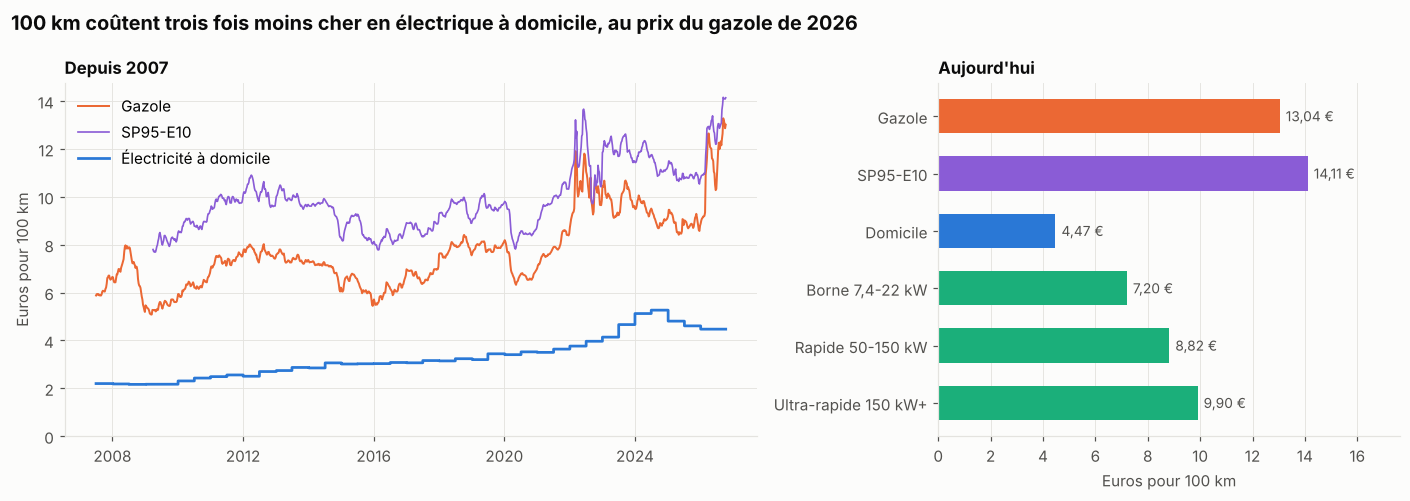

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
semaines = cout["semaine"].to_list()
ax.plot(semaines, cout["gazole"], color=ORANGE, linewidth=1.3, label="Gazole")
ax.plot(semaines, cout["e10"], color=VIOLET, linewidth=1.1, label="SP95-E10")
ax.step(semaines, cout["domicile"], where="post", color=BLEU, linewidth=1.8, label="Électricité à domicile")
ax.set_ylabel("Euros pour 100 km")
ax.yaxis.set_major_formatter(virgule)
ax.set_ylim(0, None)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Depuis 2007", fontsize=11)

ax = axes[1]
etiquettes = ["Gazole", "SP95-E10", "Domicile", "Borne 7,4-22 kW", "Rapide 50-150 kW", "Ultra-rapide 150 kW+"]
valeurs = [chiffres[f"cout_{k}"] for k in ["gazole", "e10", "domicile", "lente", "rapide", "ultra"]]
couleurs = [ORANGE, VIOLET, BLEU, AQUA, AQUA, AQUA]
ax.barh(etiquettes[::-1], valeurs[::-1], color=couleurs[::-1], height=0.6)
for yi, valeur in enumerate(valeurs[::-1]):
    ax.annotate(virgule(valeur, decimales=2) + " €", (valeur, yi), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9, color=TEXTE_2)
ax.set_xlim(0, max(valeurs) * 1.25)
ax.set_xlabel("Euros pour 100 km")
ax.xaxis.set_major_formatter(virgule)
ax.grid(axis="y", visible=False)
ax.set_title("Aujourd'hui", fontsize=11)
fig.suptitle("100 km coûtent trois fois moins cher en électrique à domicile, au prix du gazole de 2026",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "24_cout_100km")

Au prix médian des quatre dernières semaines (2,37 € le litre), 100 km au gazole coûtent **13,04 €** d'énergie, 14,11 € au SP95-E10. Rechargée à domicile au prix de référence des ménages (0,248 € le kWh), la voiture électrique fait les mêmes 100 km pour **4,47 €**, 34 % du coût du gazole : soit 1 028 € d'économie par an pour 12 000 km. Sur borne publique, les tarifs lus (tableau ci-dessus) donnent 7,20 € sur une borne de 7,4 à 22 kW, 8,82 € en recharge rapide et 9,90 € en ultra-rapide. **Au tarif médian, même la recharge ultra-rapide reste moins coûteuse que le gazole au prix actuel**, qui ne serait rattrapé qu'à 0,72 € le kWh. Ce n'était pas le cas en 2025 : au prix moyen du gazole de cette année-là (1,62 € le litre), le seuil tombait à 0,49 € le kWh, sous le tarif médian de l'ultra-rapide (0,55 €). Sur l'ensemble des semaines depuis 2007, le gazole n'a coûté plus cher que l'ultra-rapide d'aujourd'hui que 10 fois sur 100.

Le rapport entre l'électrique à domicile et le gazole a varié. Au second semestre 2007, 100 km coûtaient 6,21 € au gazole et 2,20 € en électricité à domicile (35 % du gazole). L'électricité des ménages a ensuite augmenté de façon régulière (+103 % au total), tandis que le gazole a suivi le pétrole : en 2024 et 2025, l'électrique à domicile coûtait plus de la moitié du gazole (56 % et 53 %). C'est la flambée du gazole en 2026 qui le ramène à environ un tiers.

## Limites

- **Déclarations des aménageurs** : un point de charge déclaré n'est pas forcément en service, et certains réseaux déclarent mal ou tard. Les dates de mise en service manquent pour 42 % des points, ce qui empêche de retracer précisément le déploiement.
- **Distances** : à vol d'oiseau, depuis le centre de chaque commune ; la route allonge les distances, surtout en montagne.
- **Voitures** : les voitures sont comptées au domicile de leur titulaire ; les flottes immatriculées au siège faussent les communes concernées, même après l'exclusion des sièges les plus visibles. Les voitures « rechargeables » comprennent les hybrides rechargeables.
- **Coûts** : seulement l'énergie, avec des consommations moyennes ; le prix de l'électricité à domicile comprend la part fixe de la facture (pour qui a déjà un abonnement, et avec les heures creuses, recharger coûte moins), et les tarifs publics lisibles ne couvrent que 11 % des points de 7,4 à 22 kW, 24 % des points rapides et 14 % des ultra-rapides, sans les abonnements ni les frais à la minute.

## À retenir

- La métropole compte 132 901 points de charge publics, surtout des bornes de 22 kW ou moins ; la recharge rapide (50 kW et plus) en représente un quart, sur 7 388 sites, environ quatre pour cinq stations-service.
- Les bornes ne suivent guère les voitures électriques : selon le département, on compte de 8 à 47 voitures rechargeables par point public.
- La moitié des habitants vit à moins de 1,6 km d'une recharge rapide ; 5,7 % en vivent à plus de 10 km, contre 1,1 % pour une station-service.
- **100 km coûtent 4,47 € à domicile contre 13,04 € au gazole** ; au tarif médian, même la recharge ultra-rapide (9,90 €) reste moins chère que le gazole de 2026. Ce rapport d'environ un à trois tient à la flambée du gazole de 2026 (plutôt un à deux en 2024 et 2025).
- Prochaine étape : la restitution, une application et un article qui rassemblent les six notebooks.

In [11]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_06.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1, ensure_ascii=False) + "\n")
CITES = {
 "lignes_irve": [
  157460.0,
  0.5
 ],
 "points": [
  149540.0,
  0.5
 ],
 "doublons": [
  7920.0,
  0.5
 ],
 "puissances_watts": [
  89.0,
  0.5
 ],
 "part_puissance_inconnue": [
  1.59556,
  0.05
 ],
 "part_sans_date": [
  41.665775,
  0.5
 ],
 "part_tarif_lisible": [
  10.187241,
  0.5
 ],
 "part_acces_reserve": [
  10.628354,
  0.5
 ],
 "points_publics": [
  132901.0,
  0.5
 ],
 "stations_recharge": [
  44102.0,
  0.5
 ],
 "part_points_7_22": [
  54.7,
  0.5
 ],
 "part_points_rapides": [
  25.800408,
  0.5
 ],
 "points_rapides": [
  34289.0,
  0.5
 ],
 "stations_rapides": [
  9504.0,
  0.5
 ],
 "stations_ultra": [
  4761.0,
  0.5
 ],
 "sites_rapides": [
  7388.0,
  0.5
 ],
 "sites_stations_service": [
  9189.0,
  0.5
 ],
 "stations_service": [
  9413.0,
  0.5
 ],
 "sites_rapides_pour_100": [
  80.400479,
  0.5
 ],
 "parc_debut": [
  0.40956,
  0.005
 ],
 "parc_fin": [
  2.717082,
  0.005
 ],
 "parc_multiplie": [
  6.634149,
  0.05
 ],
 "voitures_par_point": [
  20.444406,
  0.5
 ],
 "voitures_par_point_rapide": [
  79.240631,
  0.5
 ],
 "points_10k_france": [
  20.086052,
  0.05
 ],
 "points_10k_min": [
  8.576881,
  0.05
 ],
 "points_10k_max": [
  39.521284,
  0.05
 ],
 "correlation_ve_points": [
  0.074468,
  0.005
 ],
 "ve_par_point_min": [
  7.969388,
  0.5
 ],
 "ve_par_point_max": [
  46.788599,
  0.5
 ],
 "sieges_communes": [
  36.0,
  0.5
 ],
 "sieges_electriques": [
  6.755777,
  0.5
 ],
 "part_departement_declare": [
  60.922792,
  0.5
 ],
 "mediane_station": [
  1.229102,
  0.05
 ],
 "mediane_rapide": [
  1.633756,
  0.05
 ],
 "au_dela_10_rapide": [
  5.66718,
  0.05
 ],
 "habitants_10_rapide": [
  3.749736,
  0.05
 ],
 "au_dela_10_station": [
  1.131929,
  0.05
 ],
 "habitants_10_station": [
  0.74895,
  0.005
 ],
 "au_dela_15_rapide": [
  1.278438,
  0.05
 ],
 "au_dela_15_station": [
  0.075714,
  0.005
 ],
 "au_dela_10_ultra": [
  13.284451,
  0.5
 ],
 "communes_rapide_plus_loin": [
  1785.0,
  0.5
 ],
 "habitants_rapide_plus_loin": [
  1.197234,
  0.05
 ],
 "deserts_departement_max": [
  26.757838,
  0.5
 ],
 "departements_sans_desert": [
  16.0,
  0.5
 ],
 "prix_gazole": [
  2.37025,
  0.005
 ],
 "cout_gazole": [
  13.036375,
  0.005
 ],
 "cout_e10": [
  14.105,
  0.005
 ],
 "prix_kwh_domicile": [
  0.2485,
  0.0005
 ],
 "cout_domicile": [
  4.473,
  0.005
 ],
 "ratio_domicile_gazole": [
  34.311686,
  0.5
 ],
 "economie_an": [
  1027.605,
  0.5
 ],
 "cout_lente": [
  7.2,
  0.005
 ],
 "cout_rapide": [
  8.82,
  0.005
 ],
 "cout_ultra": [
  9.9,
  0.005
 ],
 "prix_kwh_equilibre": [
  0.724243,
  0.005
 ],
 "prix_gazole_2025": [
  1.616538,
  0.005
 ],
 "prix_kwh_equilibre_2025": [
  0.493942,
  0.005
 ],
 "prix_kwh_ultra": [
  0.55,
  0.005
 ],
 "part_semaines_ultra_moins_cher": [
  9.731877,
  0.5
 ],
 "cout_gazole_debut": [
  6.21113,
  0.005
 ],
 "cout_domicile_debut": [
  2.1996,
  0.005
 ],
 "ratio_debut": [
  35.413848,
  0.5
 ],
 "hausse_electricite": [
  103.355155,
  0.5
 ],
 "ratio_2024": [
  55.827461,
  0.5
 ],
 "ratio_2025": [
  52.961651,
  0.5
 ],
 "couverture_lente": [
  11.477213,
  0.5
 ],
 "couverture_rapide": [
  24.130468,
  0.5
 ],
 "couverture_ultra": [
  14.196056,
  0.5
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

70 chiffres cités, tous conformes aux calculs
